# Weather Hazard Category: model comparison, selection and promotion

Student **25945320**. Compares every exported hazard experiment on
the validation split, selects one, evaluates it **once** on the test split, and promotes it to
`models/weather_hazard/production/`.

## What this notebook is for

The five experiment notebooks each tune and report one algorithm in isolation. None of them may
touch the test split, and none of them can rank itself against the others. This notebook does
both, and it is the only place in the project where the test period is read.

## Method

| Step | What happens |
|---|---|
| 1 | Discover every bundle under `models/weather_hazard/experiments/` |
| 2 | Load the train, validation and test splits |
| 3 | Score every bundle on validation, alongside the baselines |
| 4 | Rank on macro F1 and select, with noise and baseline checks |
| 5 | Score the winner on test, once |
| 6 | Copy the winner to `production/` as `whc_model_*` files, with an audit record |

## The discipline this notebook depends on

Nothing is refitted for the comparison, so the models scored here are exactly the artefacts that
would be deployed. The selection in section 4 uses validation only. The test split is read in
section 5 and nothing after it changes the choice.

That ordering is what makes the test number worth quoting. Validation performance is optimistic
twice over — each experiment tuned against it, and this notebook then picked the best of those
tuned results. The test period has informed no decision anywhere in this project, so it is the
only honest estimate of how the promoted model will behave on dates it has never seen.

In [9]:
from __future__ import annotations

import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)


def _project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = _project_root()
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling import experiment as xp  # noqa: E402  (path must be set first)

RANDOM_STATE = 25945320
# Set to True only if you intend to refit the winner on train + validation before the test
# evaluation. See section 5 for the trade-off; the default keeps the promoted artefact byte
# identical to the one its own experiment notebook produced.
REFIT_ON_TRAIN_VAL = False

task = xp.load_task("weather_hazard")
PRODUCTION_DIR = PROJECT_ROOT / "models" / task.name / "production"

print(f"Task       : {task.target_name} ({task.kind})")
print(f"Experiments: {task.model_dir.relative_to(PROJECT_ROOT)}")
print(f"Production : {PRODUCTION_DIR.relative_to(PROJECT_ROOT)}")
print(f"Targets    : {', '.join(task.target_columns)}")

Task       : Weather Hazard Category (classification)
Experiments: models/weather_hazard/experiments
Production : models/weather_hazard/production
Targets    : whc_t7


## 1. Discover the exported experiments

Every experiment notebook writes a bundle into `models/weather_hazard/experiments/<experiment>/`
containing its fitted estimators and a metadata document. This notebook reads those bundles
rather than refitting anything, which matters for two reasons: the comparison is made against the
exact artefacts that would be deployed, and nothing here can accidentally retune a model and
report a number its own notebook never produced.

The model files are located by discovery rather than by a hard-coded filename. Two different code
paths write them — the project's deployment helper for the comfort service, the local writer for
the hazard service — so the naming is not fully under one module's control. If a bundle is found
but its model files cannot be matched to a horizon, the error names the directory and lists what
is actually there, so the fix is a one-line extension to `_key_from_filename` rather than a hunt.

A bundle that is listed with no models is a partially written experiment. Rerun that notebook
before trusting the comparison, because a model missing from this table is not a model that lost.

In [10]:
BUNDLES = xp.discover_bundles(task)

inventory = pd.DataFrame([{
    "experiment": name,
    "algorithm": bundle["metadata"].get("algorithm", "unknown"),
    "models_found": len(bundle["model_files"]),
    "horizons": sorted(str(k) for k in bundle["model_files"]),
    "has_metadata": bool(bundle["metadata"]),
} for name, bundle in BUNDLES.items()]).set_index("experiment")

print(f"Found {len(BUNDLES)} bundle(s):\n")
print(inventory.to_string())

incomplete = inventory[inventory["models_found"] == 0].index.tolist()
if incomplete:
    print(f"\nWARNING: {incomplete} contain no loadable model file. Rerun those notebooks "
          "before\n         reading the comparison: a model missing here is not a model that "
          "lost.")
if not len(BUNDLES):
    raise RuntimeError("No experiment bundles found. Run the experiment notebooks first.")

Found 4 bundle(s):

                                  algorithm  models_found horizons  has_metadata
experiment                                                                      
whc_dummy                  Dummy Classifier             1      [7]          True
whc_mlp                      MLP Classifier             1      [7]          True
whc_random_forest  Random Forest Classifier             1      [7]          True
whc_xgboost              XGBoost Classifier             1      [7]          True


## 2. Load the splits

This is the **only notebook in the project that loads the test split**, and it does so once, at
section 5, after the winner has already been chosen on validation alone. Loading it here rather
than at the point of use keeps all data access in one place, but nothing between here and the
selection reads it — that discipline is what makes the test number an honest estimate rather than
another validation score.

The training split is loaded because the generalisation columns in section 3 are informative when
ranking models, and because a refit on train plus validation is offered as an option in
section 5.

In [11]:
X, y = {}, {}
for split in ("train", "val", "test"):
    X[split], y[split] = task.load_xy(split)
    print(f"{split:5} {len(X[split]):5,} rows  {X[split].index.min():%Y-%m-%d} to "
          f"{X[split].index.max():%Y-%m-%d}")

if X["val"].index.max() >= X["test"].index.min():
    raise AssertionError("Validation dates overlap the test period.")
print("\nTest split loaded but not used until section 5.")


TARGET = task.target_columns[0]
LABELS = xp.OrdinalLabels(y["train"][TARGET])
METRIC_LABELS = list(LABELS.classes_)
REPORT_LABELS = sorted(task.class_labels)
AUX = {split: task.load_aux(split) for split in ("val", "test")}

print("\nClass distribution by split:")
print(pd.DataFrame({
    split: y[split][TARGET].value_counts() for split in ("train", "val", "test")
}).reindex(REPORT_LABELS).fillna(0).astype(int)
  .rename(index=task.class_labels).to_string())

train 2,885 rows  2016-01-31 to 2023-12-24
val     359 rows  2024-01-01 to 2024-12-24
test    358 rows  2025-01-01 to 2025-12-24

Test split loaded but not used until section 5.

Class distribution by split:
               train  val  test
whc_t7                         
Low Risk        1450  165   144
Moderate Risk   1315  178   194
High Risk        113   16    19
Extreme Risk       7    0     1


## 3. Score every experiment on validation

Each bundle's classifier is loaded and scored on the identical validation matrix, with the same
metric functions the experiment notebooks used. Nothing is refitted, so these numbers should
reproduce the ones each notebook reported; a discrepancy means a bundle is stale and that notebook
needs rerunning.

The three baselines are scored alongside as rows in the same table. They are the bar, not
competitors.

Two columns deserve more attention than macro F1 itself. **`predicted_classes`** counts how many
distinct classes each model ever predicts on validation: a model predicting one class has
collapsed onto the majority rule, and its macro F1 is arithmetically capped no matter what the
search reported. **`mean_ordinal_error`** exploits the fact that the classes are ordered, so a
model that confuses Low with Extreme is penalised more than one that confuses Low with Moderate —
a distinction macro F1 cannot make.

In [12]:
BASELINE_PREDICTIONS = xp.classification_baselines(task, X, y)

rows, loaded_models, load_failures, predictions = [], {}, {}, {}
for name, bundle in BUNDLES.items():
    if not bundle["model_files"]:
        continue
    try:
        models = xp.load_bundle_models(bundle, task.horizons)
    except FileNotFoundError as error:
        load_failures[name] = str(error)
        continue
    loaded_models[name] = models
    model = models[task.horizons[0]]
    for split in ("train", "val"):
        prediction = LABELS.decode(model.predict(X[split][task.feature_columns]))
        if split == "val":
            predictions[name] = prediction
        rows.append({
            "experiment": name, "split": split,
            **xp.classification_metrics(y[split][TARGET], prediction, METRIC_LABELS),
            "predicted_classes": int(len(np.unique(prediction))),
        })

for label, prediction in BASELINE_PREDICTIONS.items():
    rows.append({
        "experiment": label, "split": "val",
        **xp.classification_metrics(y["val"][TARGET], prediction, METRIC_LABELS),
        "predicted_classes": int(len(np.unique(prediction))),
    })

SCORES = pd.DataFrame(rows)
if load_failures:
    print("Bundles that could not be loaded:\n")
    for name, message in load_failures.items():
        print(f"  {name}: {message}\n")

VAL_SCORES = (SCORES[SCORES["split"] == "val"].set_index("experiment")
              [["macro_f1", "balanced_accuracy", "accuracy", "mean_ordinal_error",
                "predicted_classes"]]
              .sort_values("macro_f1", ascending=False))
print("Validation performance by experiment (macro F1: higher is better):\n")
print(VAL_SCORES.to_string())

collapsed = VAL_SCORES[VAL_SCORES["predicted_classes"] <= 1].index.tolist()
if collapsed:
    print(f"\nWARNING: {collapsed} predict a single class on validation. These have collapsed "
          "onto the\n         majority rule and are not usable hazard models regardless of "
          "their headline scores.")

Validation performance by experiment (macro F1: higher is better):

                   macro_f1  balanced_accuracy  accuracy  mean_ordinal_error  predicted_classes
experiment                                                                                     
whc_mlp               0.294              0.386     0.524               0.507                  3
whc_random_forest     0.283              0.387     0.554               0.471                  2
seasonal_mode         0.280              0.385     0.549               0.482                  2
whc_xgboost           0.276              0.379     0.540               0.485                  2
persistence           0.224              0.298     0.429               0.621                  3
whc_dummy             0.157              0.333     0.460               0.585                  1
majority_class        0.157              0.333     0.460               0.585                  1

         majority rule and are not usable hazard models regardless 

## 4. Rank and select

The selection rule is **highest validation macro F1**, stated before looking at the table so the
choice is not made by reading the result.

Macro F1 rather than accuracy, for the reason the dummy notebook measured rather than asserted: a
majority-class rule scores near the majority share on accuracy and near the floor on macro F1, so
selecting on accuracy would rank the useless model first.

Three checks run before the winner is accepted. It must **beat every baseline** — a model that
cannot beat the seasonal mode has learned nothing from 105 features. It must **predict more than
one class**, or it is the majority rule at greater cost. And the **margin over the runner-up** is
compared against the seed spreads the experiment notebooks recorded. That last check matters more
here than for the comfort task: with only a handful of minority-class validation days, macro F1
moves substantially when two days are reclassified, so a small margin is very likely noise.

Where the margin is within noise, the honest conclusion is that validation cannot separate the
top models, and the choice should fall to secondary grounds: interpretability, calibrated
probabilities, inference cost. The notebook says so rather than manufacturing a winner.

Selected: whc_mlp (validation macro F1 0.2943)
Runner-up: whc_random_forest, behind by 0.0108
Best baseline macro F1: 0.2796 (cleared)

Mean seed spread across experiments: 0.0192
         Validation macro F1 is not separating the top two. Choose on interpretability,
         probability calibration or inference cost, and report the tie honestly.


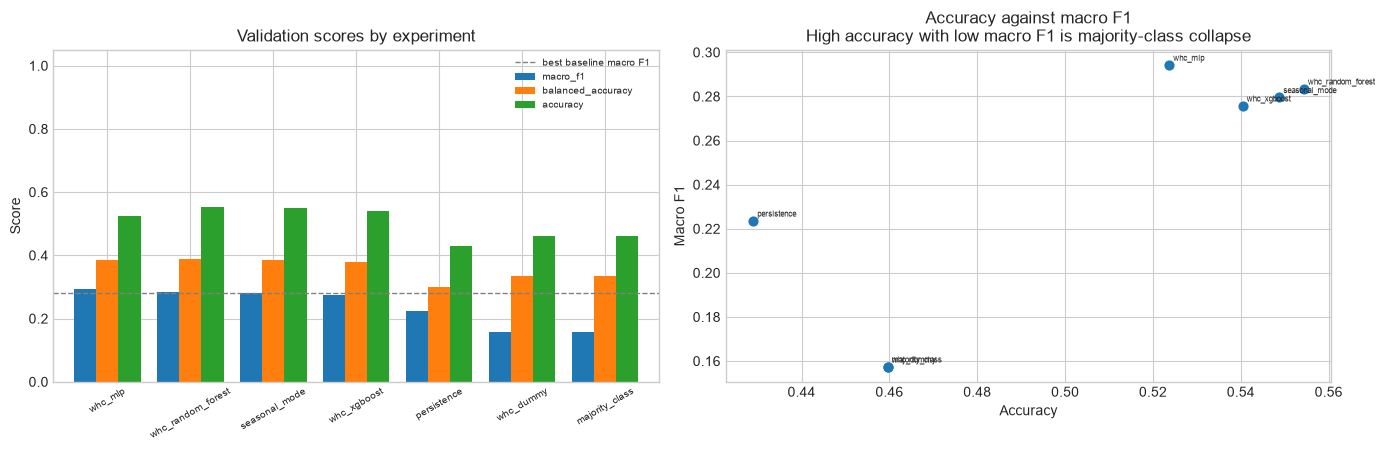

In [13]:
BASELINE_NAMES = list(BASELINE_PREDICTIONS)
candidates = VAL_SCORES.drop(index=[n for n in BASELINE_NAMES if n in VAL_SCORES.index])

BEST_EXPERIMENT = str(candidates.index[0])
best_f1 = float(candidates.loc[BEST_EXPERIMENT, "macro_f1"])
runner_up = str(candidates.index[1]) if len(candidates) > 1 else None
margin = best_f1 - float(candidates["macro_f1"].iloc[1]) if runner_up else float("nan")
best_baseline = VAL_SCORES.loc[BASELINE_NAMES, "macro_f1"].max()

print(f"Selected: {BEST_EXPERIMENT} (validation macro F1 {best_f1:.4f})")
if runner_up:
    print(f"Runner-up: {runner_up}, behind by {margin:.4f}")
print(f"Best baseline macro F1: {best_baseline:.4f} "
      f"({'cleared' if best_f1 > best_baseline else 'NOT CLEARED'})")

if best_f1 <= best_baseline:
    print("\nWARNING: no experiment beats the best informed baseline. Report that plainly - it "
          "is a\n         finding about the predictability of hazard at a 7-day lead, not a "
          "modelling failure\n         to be tuned away.")
if VAL_SCORES.loc[BEST_EXPERIMENT, "predicted_classes"] <= 1:
    print("\nWARNING: the selected model predicts a single class. It is the majority rule in "
          "disguise.")

seed_spreads = []
for name, bundle in BUNDLES.items():
    for entry in bundle["metadata"].get("seed_stability", []):
        seed_spreads.append(entry.get("seed_spread", np.nan))
typical_spread = float(np.nanmean(seed_spreads)) if seed_spreads else float("nan")
print(f"\nMean seed spread across experiments: {typical_spread:.4f}")
if runner_up and not np.isnan(typical_spread) and margin < typical_spread:
    print(f"WARNING: the {margin:.4f} margin over {runner_up} is smaller than the typical seed "
          "spread.\n         Validation macro F1 is not separating the top two. Choose on "
          "interpretability,\n         probability calibration or inference cost, and report "
          "the tie honestly.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
VAL_SCORES[["macro_f1", "balanced_accuracy", "accuracy"]].plot.bar(ax=axes[0], width=0.8)
axes[0].axhline(best_baseline, ls="--", lw=1.0, color="grey", label="best baseline macro F1")
axes[0].set(title="Validation scores by experiment", ylabel="Score", xlabel="", ylim=(0, 1.05))
axes[0].tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)

axes[1].scatter(VAL_SCORES["accuracy"], VAL_SCORES["macro_f1"], s=40)
for name, row in VAL_SCORES.iterrows():
    axes[1].annotate(name, (row["accuracy"], row["macro_f1"]), fontsize=6,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set(title="Accuracy against macro F1\nHigh accuracy with low macro F1 is majority-class "
                  "collapse",
            xlabel="Accuracy", ylabel="Macro F1")
fig.tight_layout()
task.save_figure(fig, "whc-comparison-validation")
plt.show()

## 5. Single test evaluation

The test split is scored **once**, here, for the selected model only. No other experiment is
scored on it, and nothing after this point changes the selection.

That restraint is the entire value of the number. Validation performance carries selection
optimism — every experiment tuned against it, and this notebook then chose the best of those
tuned results, so the winning validation macro F1 is biased high twice over. The test period has
informed no decision anywhere in this project, so its macro F1 is the estimate to quote.

Expect a drop, and expect it to be larger than it would be for the comfort task. Macro F1 on a
period containing only a handful of minority-class days is high variance, and the winner was
chosen partly because it happened to get some of those days right in 2024. The test confusion
matrix is the honest picture and belongs in the report ahead of any single number.

**Refitting on train plus validation** is offered but disabled by default, for the same reason as
the comfort task: the promoted artefact would no longer be the one its experiment notebook
produced and documented. Here there is an additional argument against it — refitting changes the
class balance the model was tuned against, and the hyperparameters selected under one balance are
not necessarily right under another.

Test performance (scored once, never used for any decision):

                accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                
whc_mlp            0.447              0.236     0.228        0.438         0.236            0.224               0.592
majority_class     0.402              0.250     0.143        0.231         0.250            0.101               0.656
persistence        0.464              0.241     0.241        0.464         0.241            0.241               0.589

Validation macro F1 0.2943 -> test macro F1 0.2284 (-0.0659 optimism)

Per-class test performance (all four brief classes shown):

            category  precision  recall    f1  support  predicted
class                                                            
0           Low Risk      0.370   0.465 0.412      144        181
1      Moderate Ri

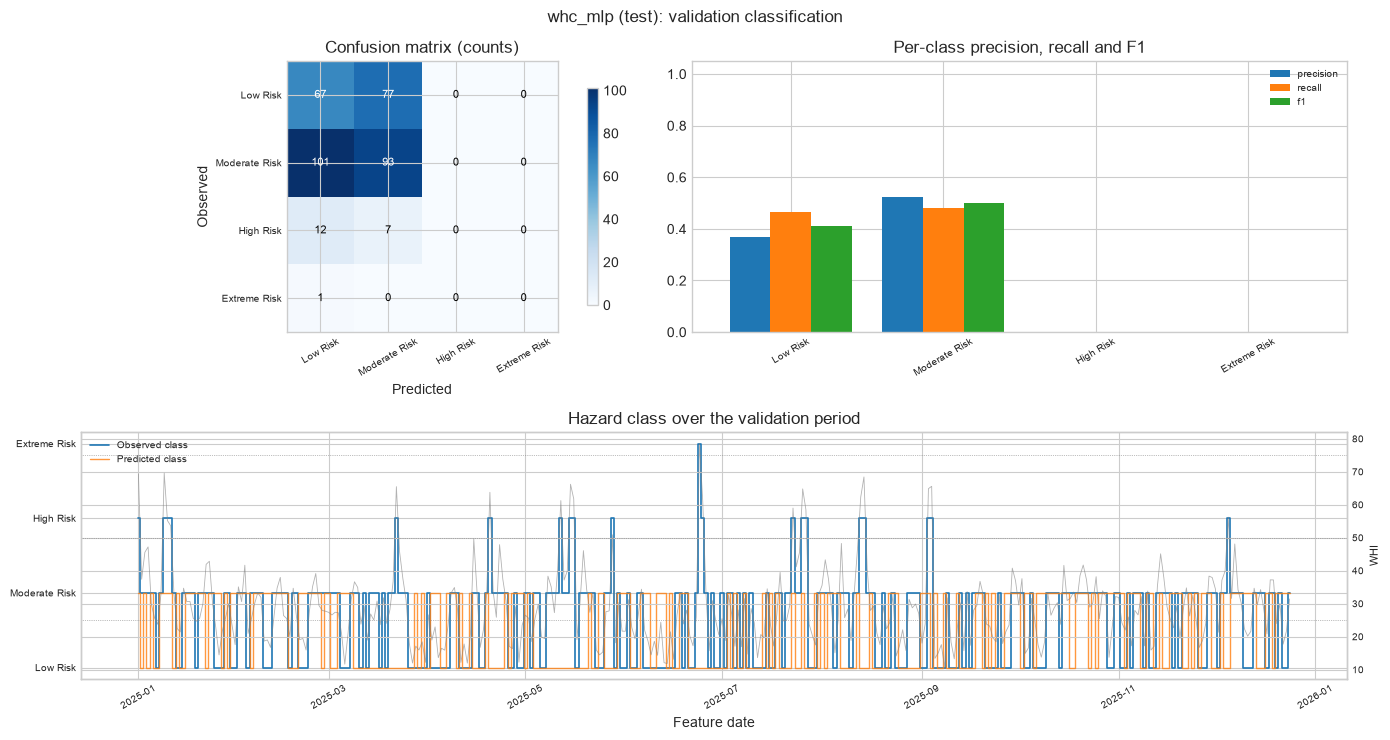

In [14]:
selected_model = loaded_models[BEST_EXPERIMENT][task.horizons[0]]

if REFIT_ON_TRAIN_VAL:
    from sklearn.base import clone

    try:
        combined_X = pd.concat([X["train"], X["val"]])
        combined_y = pd.concat([y["train"][TARGET], y["val"][TARGET]])
        fresh = clone(selected_model)
        fresh.fit(combined_X[task.feature_columns], LABELS.encode(combined_y))
        selected_model = fresh
        print(f"Refitted on {len(combined_X):,} train + validation rows.\n")
    except Exception as error:
        print(f"Refit failed ({type(error).__name__}: {error}); keeping the original fit.\n")

TEST_PREDICTION = LABELS.decode(selected_model.predict(X["test"][task.feature_columns]))

rows = [{"model": BEST_EXPERIMENT,
         **xp.classification_metrics(y["test"][TARGET], TEST_PREDICTION, METRIC_LABELS)}]
test_baselines = {
    "majority_class": np.full(len(X["test"]),
                              int(y["train"][TARGET].mode().iloc[0]), dtype=int),
    "persistence": xp.hazard_class_from_whi(X["test"][task.persistence_column]),
}
for label, prediction in test_baselines.items():
    rows.append({"model": label,
                 **xp.classification_metrics(y["test"][TARGET], prediction, METRIC_LABELS)})
TEST_RESULTS = pd.DataFrame(rows).set_index("model")
print("Test performance (scored once, never used for any decision):\n")
print(TEST_RESULTS.to_string())

print(f"\nValidation macro F1 {best_f1:.4f} -> test macro F1 "
      f"{TEST_RESULTS.loc[BEST_EXPERIMENT, 'macro_f1']:.4f} "
      f"({TEST_RESULTS.loc[BEST_EXPERIMENT, 'macro_f1'] - best_f1:+.4f} optimism)")

fig, PER_CLASS = xp.plot_classification_validation(
    task, X["test"].index, y["test"][TARGET], TEST_PREDICTION, REPORT_LABELS,
    f"{BEST_EXPERIMENT} (test)", "whc-comparison-test",
    whi=AUX["test"][task.auxiliary_columns[0]],
)
print("\nPer-class test performance (all four brief classes shown):\n")
print(PER_CLASS.to_string())
plt.show()

## 6. Promote to production

The selected bundle is copied from `experiments/` to `models/weather_hazard/production/`, together with
a `whc_model_promotion.json` recording what was chosen, on what evidence, and when.

Files are **renamed** on the way in. Experiment directories keep algorithm-specific names such as
`whc_mlp_h7.joblib`; production always uses the stable `whc_model_*` convention
(`whc_model_h7.joblib`, `whc_model_manifest.json`, `whc_model_metadata.json`,
`whc_model_features.json`, `whc_model_promotion.json`). The API can therefore load the same paths
after every promotion, regardless of which experiment won.

Copying rather than moving matters: the experiment record stays intact, so the comparison remains
reproducible after promotion. The production directory is **replaced** rather than merged, so
exactly one model is live per task and the API cannot pick up a stale artefact left by a previous
promotion.

`whc_model_promotion.json` is the audit trail. It records the selection metric and rule, the
validation ranking that produced the winner, the test metrics, and any warnings raised above —
including a margin within seed noise, or a failure to beat a baseline. A promotion that happened
despite a warning should be readable as such months later, which is the point of writing the
warnings into the record rather than only printing them.

**The FastAPI repository should load from `production/`, never from `experiments/`.** That is what
makes the deployment boundary real rather than a naming convention.

In [15]:
WARNINGS = []
if best_f1 <= best_baseline:
    WARNINGS.append("Selected model does not beat the best informed baseline.")
if VAL_SCORES.loc[BEST_EXPERIMENT, "predicted_classes"] <= 1:
    WARNINGS.append("Selected model predicts a single class on validation.")
if runner_up and not np.isnan(typical_spread) and margin < typical_spread:
    WARNINGS.append(f"Margin over {runner_up} ({margin:.4f}) is within the typical seed spread "
                    f"({typical_spread:.4f}); the ranking may not be separating the top two.")
if collapsed:
    WARNINGS.append(f"Experiments collapsed onto a single class: {collapsed}")
print("Warnings to record with the promotion:" if WARNINGS else "No warnings to record.")
for message in WARNINGS:
    print(f"  - {message}")

Warnings to record with the promotion:
  - Margin over whc_random_forest (0.0108) is within the typical seed spread (0.0192); the ranking may not be separating the top two.
  - Experiments collapsed onto a single class: ['whc_dummy', 'majority_class']


In [16]:
PROMOTION_RECORD = {
    "promoted_at": datetime.now(timezone.utc).isoformat(),
    "student_id": "25945320",
    "task": task.name,
    "target": task.target_name,
    "selected_experiment": BEST_EXPERIMENT,
    "selection_metric": "validation macro-averaged F1 over classes seen in training",
    "selection_rule": "highest validation macro F1, stated before inspecting the results",
    "selection_data": "validation split only; the test split informed no decision",
    "runner_up": runner_up,
    "margin_over_runner_up": None if runner_up is None else float(margin),
    "typical_seed_spread": None if np.isnan(typical_spread) else float(typical_spread),
    "validation_ranking": VAL_SCORES.reset_index().to_dict(orient="records"),
    "test_metrics": TEST_RESULTS.reset_index().to_dict(orient="records"),
    "refit_on_train_val": bool(REFIT_ON_TRAIN_VAL),
    "source_bundle": str(BUNDLES[BEST_EXPERIMENT]["dir"].relative_to(PROJECT_ROOT)),
    "feature_columns": task.feature_columns,
    "feature_column_order_is_significant": True,
    "history_days": int(task.metadata.get("warmup_days", 30)),
    "warnings": WARNINGS,
}

destination = xp.promote_bundle(task, BUNDLES[BEST_EXPERIMENT], PROMOTION_RECORD)
print(f"Promoted {BEST_EXPERIMENT} -> {destination.relative_to(PROJECT_ROOT)}")
print(f"Production files use the stable `{task.production_stem}_*` names:\n")
for path in sorted(destination.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(destination)}  ({path.stat().st_size / 1024:.1f} KB)")

if WARNINGS:
    print(f"\nPromoted with the following warnings recorded in {task.production_stem}_promotion.json:")
    for message in WARNINGS:
        print(f"  - {message}")

Promoted whc_mlp -> models/weather_hazard/production
Production files use the stable `whc_model_*` names:

  whc_model_features.json  (2.4 KB)
  whc_model_h7.joblib  (89.0 KB)
  whc_model_manifest.json  (2.9 KB)
  whc_model_metadata.json  (11.2 KB)
  whc_model_promotion.json  (6.6 KB)

Promoted with the following warnings recorded in whc_model_promotion.json:
  - Margin over whc_random_forest (0.0108) is within the typical seed spread (0.0192); the ranking may not be separating the top two.
  - Experiments collapsed onto a single class: ['whc_dummy', 'majority_class']


## 7. Conclusions

Points to carry into the report:

- **The selection, and how close it was.** Name the winner, the runner-up and the margin, and say
  explicitly whether that margin survives the seed-spread check. A close result reported as a
  clear win is the most common way a model comparison misleads.
- **The test number, not the validation number.** Quote test macro F1 as the performance estimate.
  The validation figure selected the model and cannot also measure it.
- **The size of the optimism.** The validation-to-test gap quantifies how much the selection
  overfitted 2024. A large gap belongs in the limitations section.
- **What beat the baselines, and where.** A model that cannot beat the seasonal mode has learned nothing from 105 engineered features.
- **What is now live.** `models/weather_hazard/production/` holds exactly one bundle, named
  `whc_model_*` regardless of which experiment won, and `whc_model_promotion.json` records why.
  The FastAPI service should load those stable filenames.

Rerun this notebook whenever an experiment is rerun. A promotion record referring to a bundle that
has since been overwritten is worse than none, because it looks authoritative.